# Customising plots

## Learning objectives

By the end of this notebook you will be able to:

- set titles, axis labels, limits and ticks
- add legends and annotations
- control colours, markers, line styles and colour maps
- apply styles and gridlines
- set figure size and resolution, and export to PNG, JPEG, SVG and PDF

## Introduction

A default plot shows the data; a customised plot communicates it. This notebook covers the settings
you will use most, then saving figures for reports and publications.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAW = "../datasets/raw/"

In [2]:
labs = pd.read_csv(RAW + "lab_results.csv")
patients = pd.read_csv(RAW + "patients.csv")
df = labs.merge(patients[["patient_id", "group", "age"]], on="patient_id")

## Titles, labels, limits and ticks

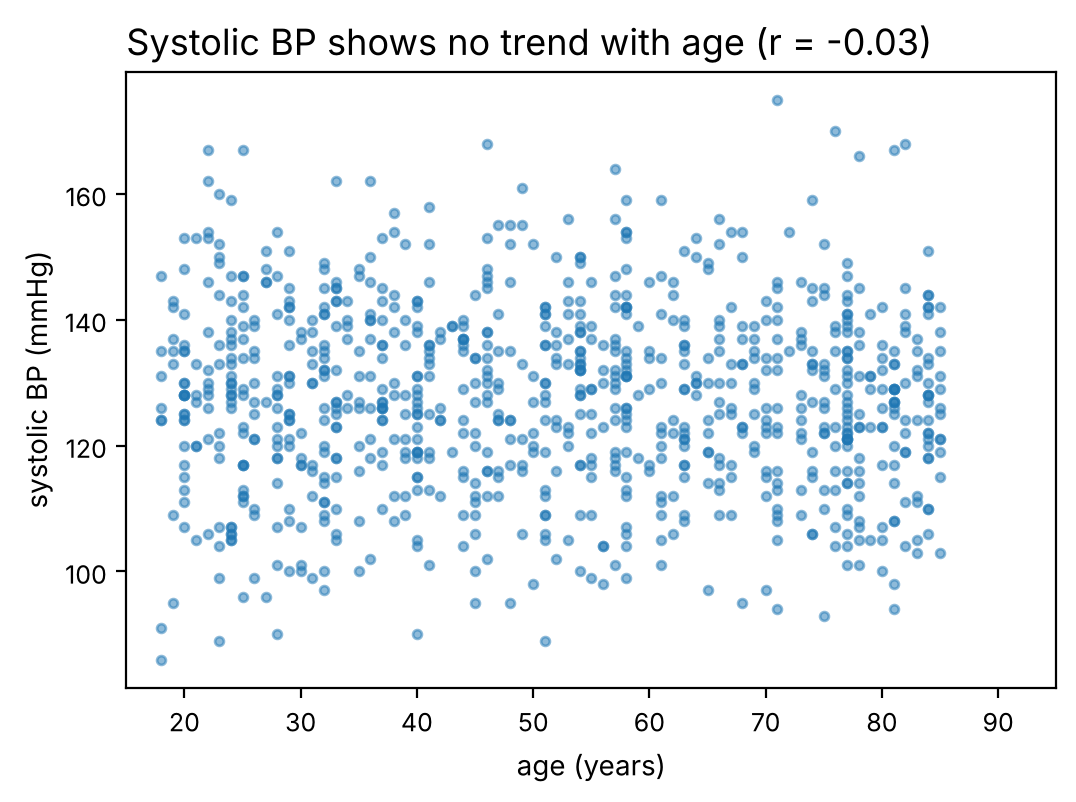

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["age"], df["systolic_bp"], s=10, alpha=0.5)
r = df["age"].corr(df["systolic_bp"])
ax.set_title(f"Systolic BP shows no trend with age (r = {r:.2f})", fontsize=13, loc="left")
ax.set_xlabel("age (years)")
ax.set_ylabel("systolic BP (mmHg)")
ax.set_xlim(15, 95)
ax.set_xticks(range(20, 100, 10))
ax.tick_params(labelsize=9)
plt.show()

A title that **states the finding** ("no trend with age") helps more than one that only names the variables.
(The data in this course are simulated; in real populations blood pressure does tend to rise with age.)

## Colours, markers and line styles

Colours can be names (`"steelblue"`), hex codes (`"#1f77b4"`) or the default cycle `"C0"`, `"C1"`, ...

| marker | | line style | |
|---|---|---|---|
| `"o"` | circle | `"-"` | solid |
| `"s"` | square | `"--"` | dashed |
| `"^"` | triangle | `":"` | dotted |
| `"x"` | cross | `"-."` | dash-dot |

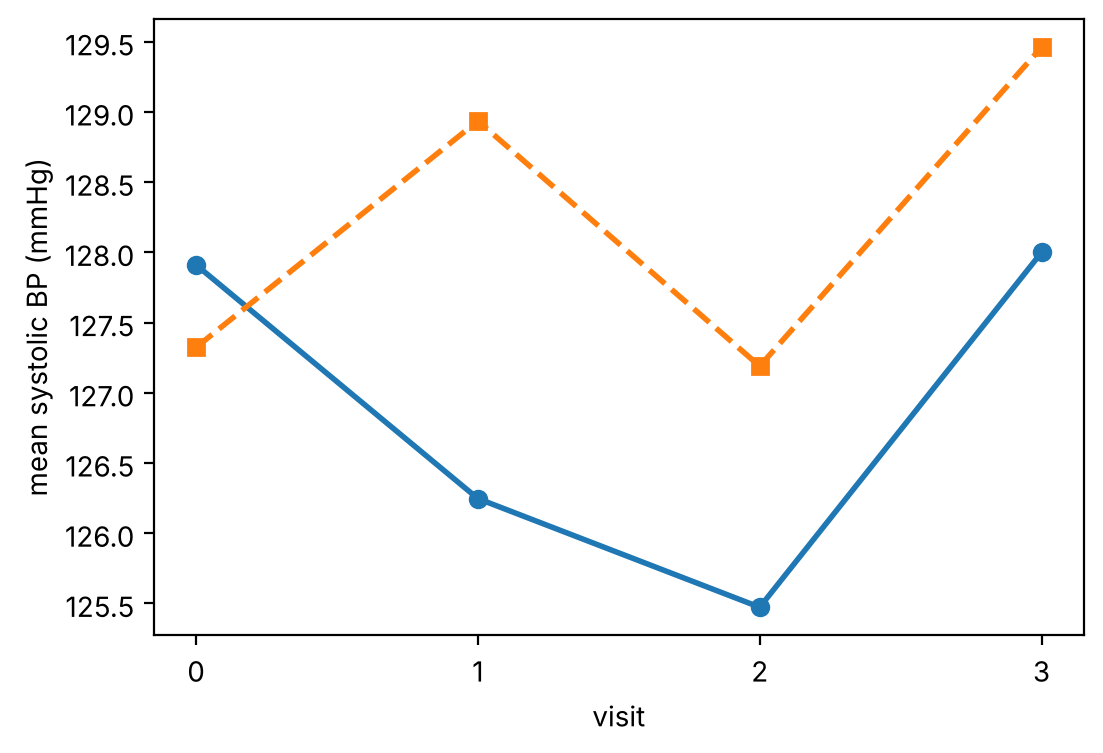

In [4]:
means = df.groupby(["visit", "group"])["systolic_bp"].mean().unstack()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(means.index, means["Control"], color="C0", marker="o", linestyle="-", linewidth=2, label="Control")
ax.plot(means.index, means["Treatment"], color="C1", marker="s", linestyle="--", linewidth=2, label="Treatment")
ax.set_xticks(means.index)
ax.set_xlabel("visit")
ax.set_ylabel("mean systolic BP (mmHg)")
plt.show()

Different markers and line styles as well as colours mean the chart still works in greyscale print and
for readers with colour-vision deficiency.

## Legends

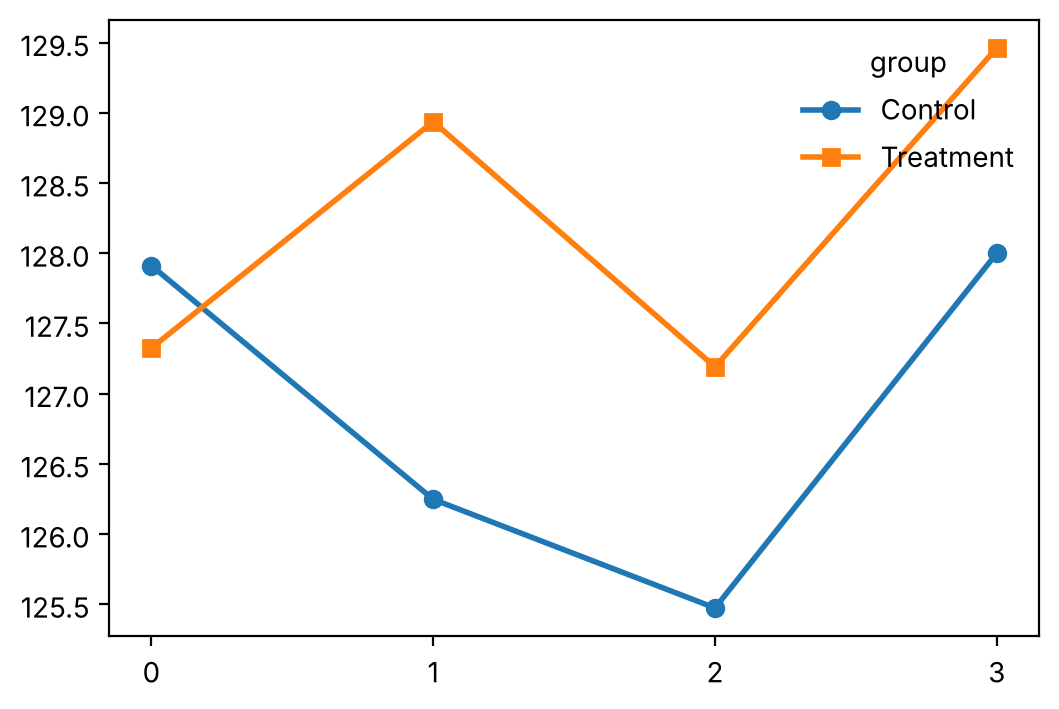

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for g, marker in [("Control", "o"), ("Treatment", "s")]:
    ax.plot(means.index, means[g], marker=marker, linewidth=2, label=g)
ax.legend(title="group", loc="upper right", frameon=False)
ax.set_xticks(means.index)
plt.show()

`loc` places the legend (`"best"`, `"upper left"`, `"lower right"`, ...). For a few lines, labelling the
lines directly is often clearer than a legend:

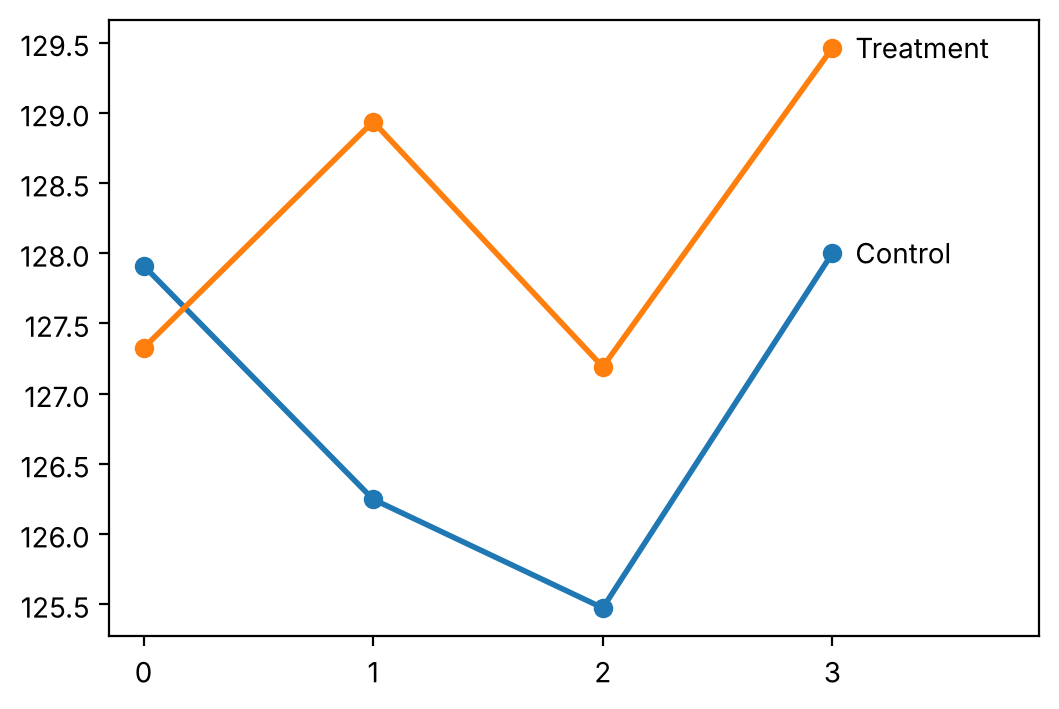

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for g in ["Control", "Treatment"]:
    ax.plot(means.index, means[g], marker="o", linewidth=2)
    ax.text(means.index[-1] + 0.1, means[g].iloc[-1], g, va="center")
ax.set_xlim(right=means.index[-1] + 0.9)
ax.set_xticks(means.index)
plt.show()

## Annotations

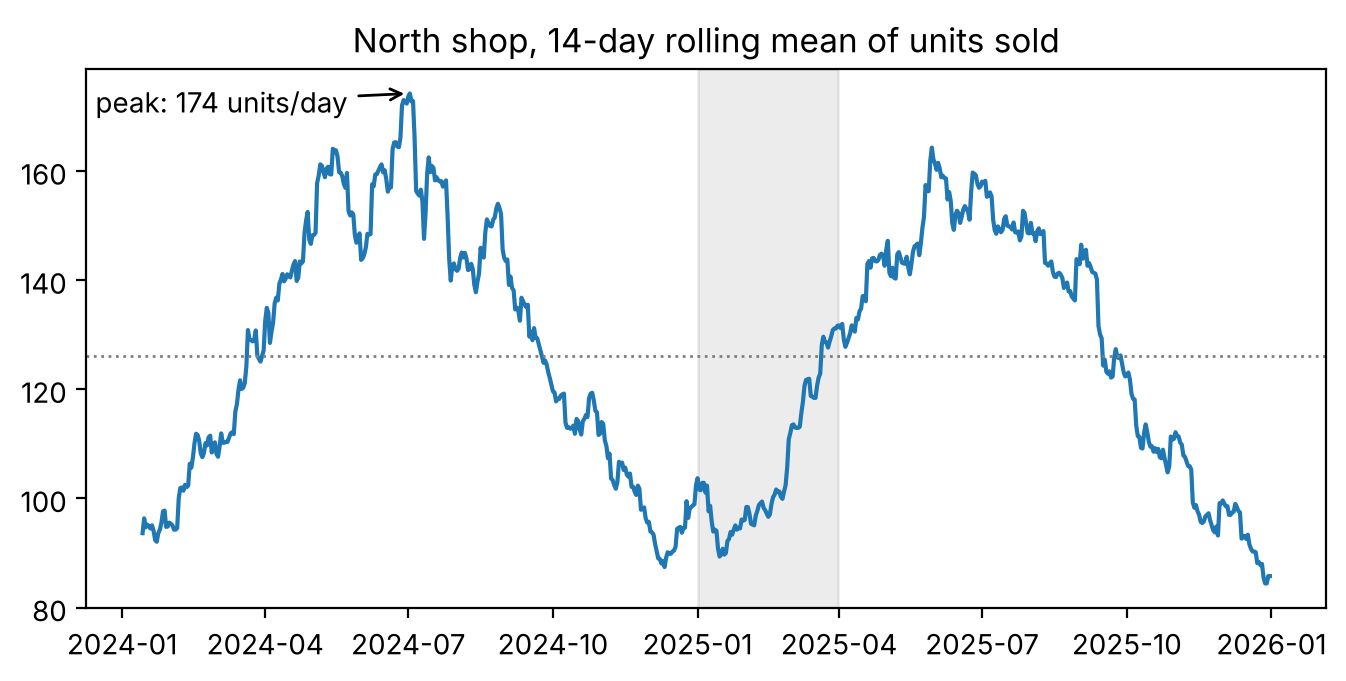

In [7]:
sales = pd.read_csv(RAW + "daily_sales.csv", parse_dates=["date"])
north = sales[sales["shop"] == "North"].set_index("date")["units"].rolling(14).mean()
peak = north.idxmax()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(north.index, north.values, linewidth=1.5)
ax.annotate(f"peak: {north.max():.0f} units/day", xy=(peak, north.max()),
            xytext=(peak - pd.Timedelta(days=200), north.max() * 0.98),
            arrowprops={"arrowstyle": "->"})
ax.axhline(north.mean(), color="grey", linestyle=":", linewidth=1)
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-03-31"), color="grey", alpha=0.15)
ax.set_title("North shop, 14-day rolling mean of units sold")
plt.show()

- `annotate` draws text with an optional arrow to a point
- `axhline` / `axvline` draw reference lines
- `axhspan` / `axvspan` shade a range (here, the first quarter of 2025)

## Gridlines and spines

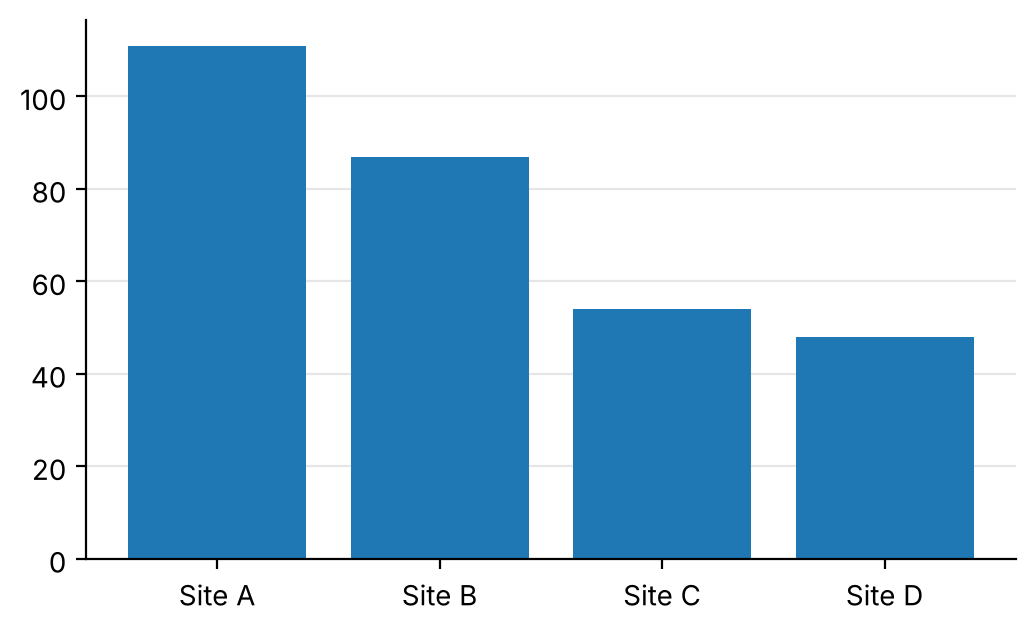

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Site A", "Site B", "Site C", "Site D"], patients["site"].value_counts().sort_index())
ax.grid(axis="y", color="0.9")
ax.set_axisbelow(True)                  # gridlines behind the bars
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Styles

A style changes many defaults at once. `plt.style.available` lists them. Use `with plt.style.context`
to try one without changing everything after it.

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6']


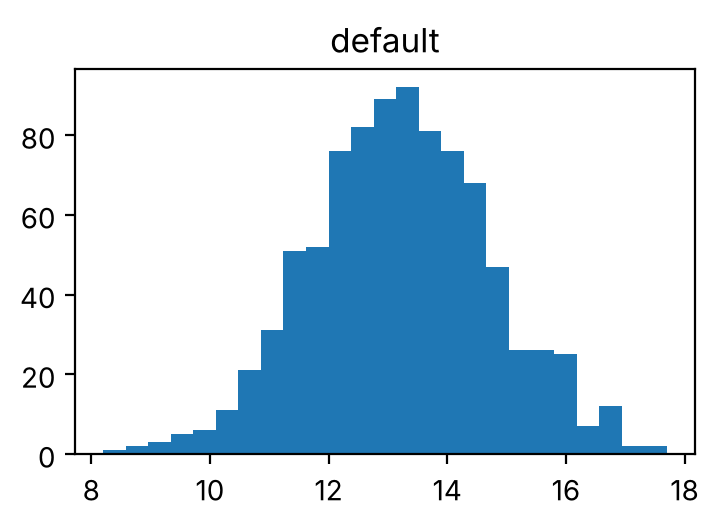

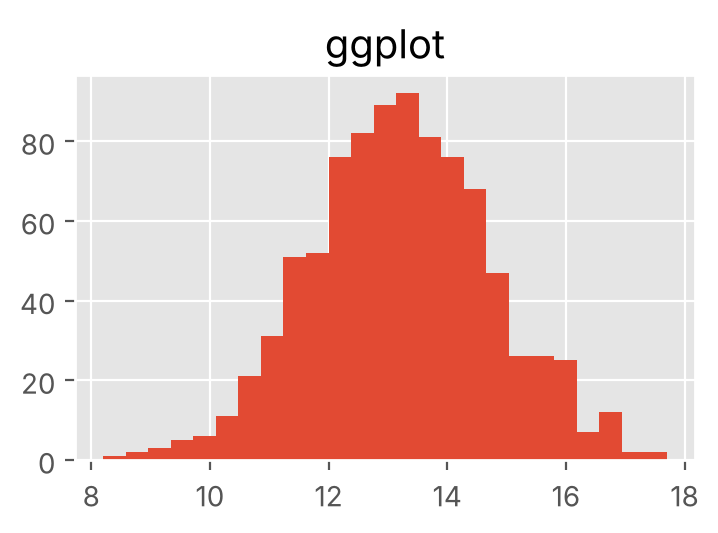

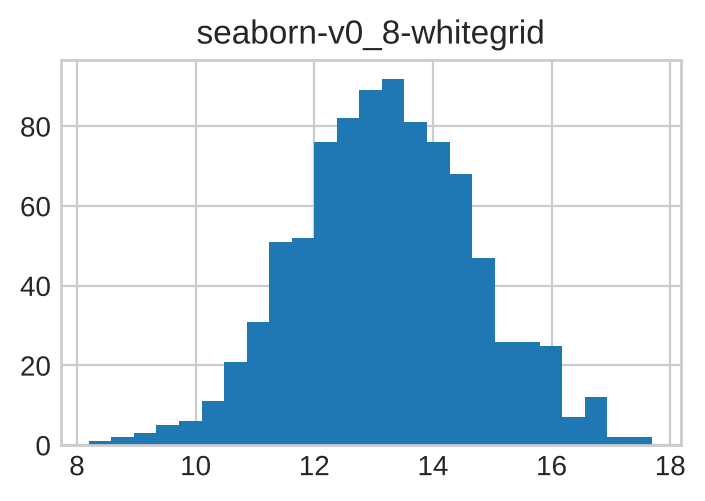

In [9]:
print(plt.style.available[:10])
for style in ["default", "ggplot", "seaborn-v0_8-whitegrid"]:
    with plt.style.context(style):
        fig, ax = plt.subplots(figsize=(4, 2.5))
        ax.hist(labs["haemoglobin_g_dl"], bins=25)
        ax.set_title(style)
        plt.show()

## Colour maps

A colour map turns numbers into colours. Use **sequential** maps (`viridis`, `Blues`) for values from
low to high, and **diverging** maps (`RdBu`, `coolwarm`) for values either side of a meaningful centre
such as zero. `viridis` is designed to be readable in greyscale and by people with colour-vision
deficiency; avoid `jet` and `rainbow`, which create false boundaries.

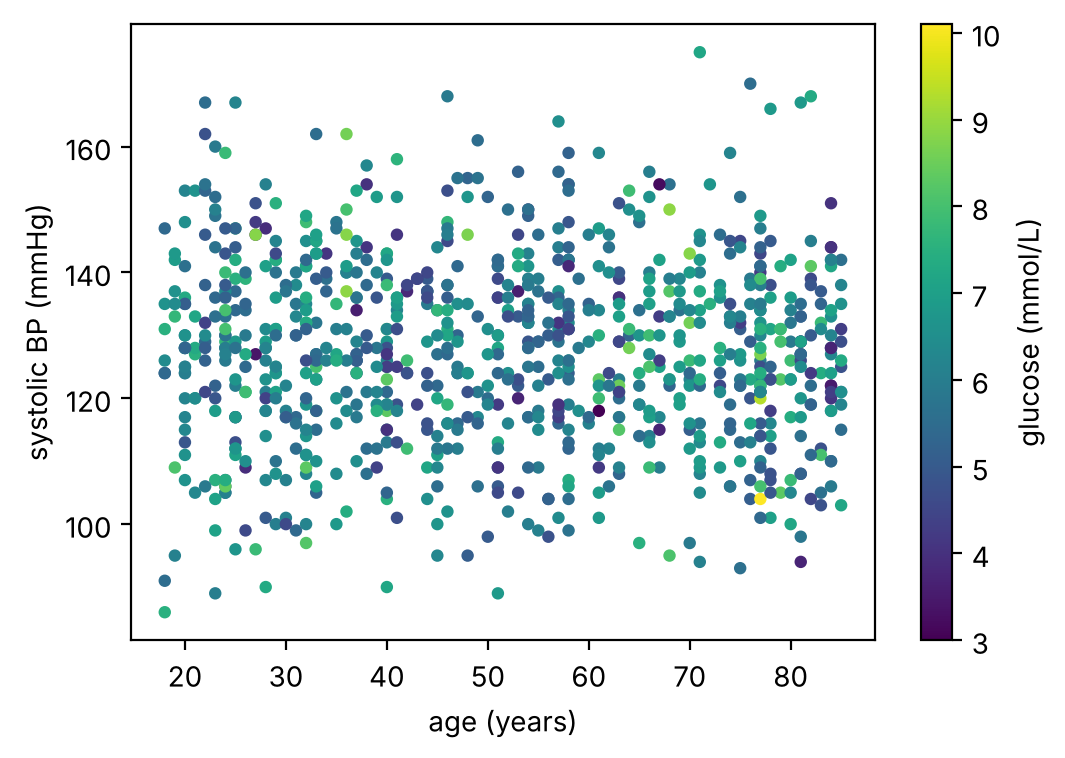

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
pts = ax.scatter(df["age"], df["systolic_bp"], c=df["glucose_mmol"], cmap="viridis", s=12)
fig.colorbar(pts, ax=ax, label="glucose (mmol/L)")
ax.set_xlabel("age (years)")
ax.set_ylabel("systolic BP (mmHg)")
plt.show()

## Figure size and resolution

`figsize=(width, height)` is in inches. `dpi` (dots per inch) sets the resolution: about 100 for screens,
300 or more for print. A figure 6 inches wide saved at 300 dpi is 1800 pixels wide.

## Exporting

| format | type | use for |
|---|---|---|
| PNG | raster (pixels) | slides, web, documents |
| JPEG | raster, lossy | photos; blurs sharp lines, so avoid for charts |
| SVG | vector | web, editing in Inkscape or Illustrator |
| PDF | vector | LaTeX, journals, printing |

Vector formats stay sharp at any size.

In [11]:
from pathlib import Path
out = Path("figures_demo")
out.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(labs["glucose_mmol"], bins=30, edgecolor="white")
ax.set_xlabel("glucose (mmol/L)")
ax.set_ylabel("results")

fig.savefig(out / "glucose.png", dpi=300, bbox_inches="tight")
fig.savefig(out / "glucose.jpg", dpi=200, bbox_inches="tight")
fig.savefig(out / "glucose.svg", bbox_inches="tight")
fig.savefig(out / "glucose.pdf", bbox_inches="tight")
plt.close(fig)

for f in sorted(out.iterdir()):
    print(f"{f.name:14} {f.stat().st_size / 1024:7.1f} KB")

glucose.jpg       47.8 KB
glucose.pdf       10.0 KB
glucose.png       40.4 KB
glucose.svg       25.4 KB


`bbox_inches="tight"` trims empty margins so labels are not cut off. `plt.close(fig)` frees memory and
stops the figure also displaying in the notebook. Call `savefig` before `plt.show()`: after show, the
figure may be empty.

In [12]:
import shutil
shutil.rmtree(out)

## Setting defaults for a whole notebook

`plt.rcParams` holds the defaults. Setting a few at the top of a notebook keeps all its figures
consistent:

```python
plt.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "font.size": 10,
})
```

## Practise

Exercises for this folder are in `exercises/Matplotlib_Exercises.ipynb`.

## Further reading

- [Matplotlib user guide](https://matplotlib.org/stable/users/index.html)
- [Customising Matplotlib with style sheets and rcParams](https://matplotlib.org/stable/users/explain/customizing.html)
- [Choosing colormaps](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
- [Annotations](https://matplotlib.org/stable/users/explain/text/annotations.html)
- [savefig reference](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html)